> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Módulo 56 | Temperatura anual de Nueva York: ARIMA Box-Jenkins
**Javier Bueno Sánchez · Ciencia de datos**  
**Fuente:** `TempNY.csv`, serie anual 1870-2020 facilitada con la actividad; repositorio EBAC: https://github.com/JoseRaulCastro/EBAC/blob/main/TempNY.csv.  
**Objetivo:** escoger un ARIMA con los datos 1870-2004 y pronosticar 2005-2020, con intervalos del 90 %. Temperaturas en grados Fahrenheit (°F), según la escala de los valores de origen; verificar metadatos de la fuente antes de cambiar unidades.

## 1. Preparación y partición temporal
La serie contiene 151 años consecutivos. La columna sin nombre está completamente vacía. Reservamos los **últimos 16 años** (2005-2020) como prueba: `floor(0.90 × 151) = 135` años de entrenamiento. No mezclamos años ni ajustamos modelos con la prueba.

Total: 151; entrenamiento: 135 (1870-2004); prueba: 16 (2005-2020)
       Temperatura (°F)
count            151.00
mean              54.00
std                1.70
min               49.34
25%               52.96
50%               54.02
75%               55.18
max               57.31


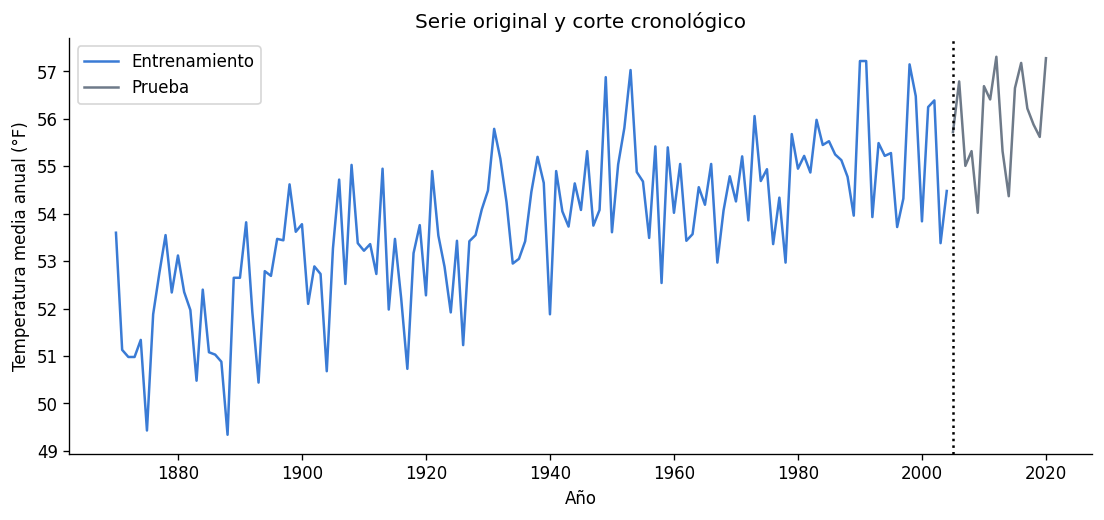

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_squared_error, mean_absolute_error
from IPython.display import display
plt.rcParams.update({'figure.figsize':(11,4.5), 'axes.spines.top':False,'axes.spines.right':False})
AZUL='#3A7BD5'; GRIS='#6E7A89'
raw=pd.read_csv('TempNY.csv')
assert raw['Year'].tolist()==list(range(1870,2021))
y=pd.Series(raw['Average'].to_numpy(dtype=float),index=pd.Index(raw['Year'],name='Año'),name='Temperatura (°F)')
assert y.notna().all()
n_train=int(np.floor(.9*len(y))); train=y.iloc[:n_train]; test=y.iloc[n_train:]
print(f'Total: {len(y)}; entrenamiento: {len(train)} ({train.index.min()}-{train.index.max()}); prueba: {len(test)} ({test.index.min()}-{test.index.max()})')
display(y.describe().to_frame('Temperatura (°F)').round(2))
fig,ax=plt.subplots();ax.plot(train.index,train,color=AZUL,label='Entrenamiento');ax.plot(test.index,test,color=GRIS,label='Prueba');ax.axvline(test.index.min(),ls=':',color='black');ax.set(xlabel='Año',ylabel='Temperatura media anual (°F)',title='Serie original y corte cronológico');ax.legend();plt.show()

## 2. Estacionariedad y grado de integración
La prueba de Dickey-Fuller aumentada (ADF) contrasta la hipótesis nula de raíz unitaria. Usamos constante y selección automática de rezagos por AIC; con umbral de 5 %, un valor p ≥ 0.05 impide rechazar la no estacionariedad. Se calculan diferencias **únicamente sobre entrenamiento**; `d` es el primer orden cuyo p cae por debajo de 0.05. La ADF es una prueba, no una gráfica: representamos tanto la serie como los resultados numéricos.

cell_4:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
cell_4:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
cell_4:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_obje

,d,ADF,p,Rezagos,Observaciones,Crítico 5 %
0,0,-1.71771,0.42201,7,127,-2.88458
1,1,-8.46058,0.00000,6,127,-2.88458
2,2,-6.83505,0.00000,12,120,-2.88594


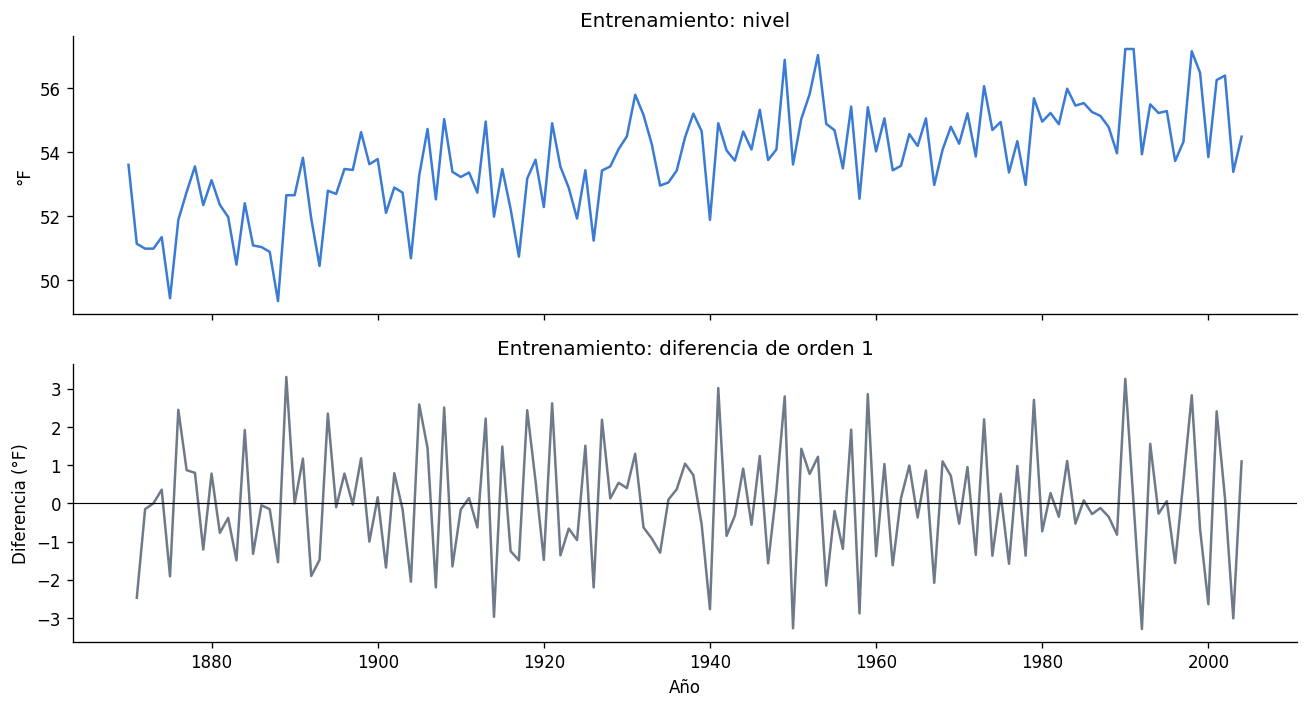

In [5]:
rows=[]; d=None
for k in range(3):
    serie=train.diff(k).dropna() if k==1 else train.diff().diff().dropna() if k==2 else train
    res=adfuller(serie,autolag='AIC',regression='c')
    rows.append({'d':k,'ADF':res[0],'p':res[1],'Rezagos':res[2],'Observaciones':res[3],'Crítico 5 %':res[4]['5%']})
    if d is None and res[1]<.05: d=k
adf_tab=pd.DataFrame(rows)
display(adf_tab.round(5))
if d is None: raise ValueError('No se alcanzó estacionariedad hasta d=2; revisar especificación')
print(f'Primera diferencia estacionaria: d={d}. La serie original presenta p={adf_tab.loc[0,"p"]:.4g}; tras d={d}, p={adf_tab.loc[d,"p"]:.4g}.')
fig,axs=plt.subplots(2,1,figsize=(11,6),sharex=True)
axs[0].plot(train.index,train,color=AZUL);axs[0].set(ylabel='°F',title='Entrenamiento: nivel')
z=train.diff(d).dropna() if d else train
axs[1].plot(z.index,z,color=GRIS);axs[1].axhline(0,color='black',lw=.7);axs[1].set(xlabel='Año',ylabel='Diferencia (°F)',title=f'Entrenamiento: diferencia de orden {d}')
plt.tight_layout();plt.show()

## 3. Identificación y selección por AIC
ACF y PACF de la serie diferenciada sirven para orientar órdenes MA y AR. Se comparan **nueve** combinaciones `(p,d,q)` con `p,q ∈ {0,1,2}` y el `d` fijado por ADF. El AIC solo compara candidatos ajustados **sobre el mismo entrenamiento**: menor AIC favorece equilibrio entre ajuste y complejidad. Se registran errores de convergencia y no se escogen modelos que fallan. En modelos con `d>0` no incluimos tendencia determinista ni deriva; esto mantiene comparables las nueve especificaciones.

Modelo elegido ARIMA(0, 1, 1), AIC=433.657, BIC=439.452; 9 candidatos convergentes.
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  135
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -214.828
Date:                Mon, 28 Sep 2026   AIC                            433.657
Time:                        11:15:55   BIC                            439.452
Sample:                             0   HQIC                           436.012
                                - 135                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8538      0.050    -17.078      0.000      -0.952      -0.756
sigma2         1.4316      0.211      6.780    

,p,d,q,AIC,BIC,Convergió
0,0,1,1,433.657,439.452,True
1,1,1,1,435.230,443.924,True
2,0,1,2,435.280,443.973,True
3,2,1,2,436.813,451.303,True
4,2,1,1,436.824,448.416,True
5,1,1,2,437.026,448.617,True
6,2,1,0,453.556,462.249,True
7,1,1,0,462.295,468.091,True
8,0,1,0,496.475,499.373,True


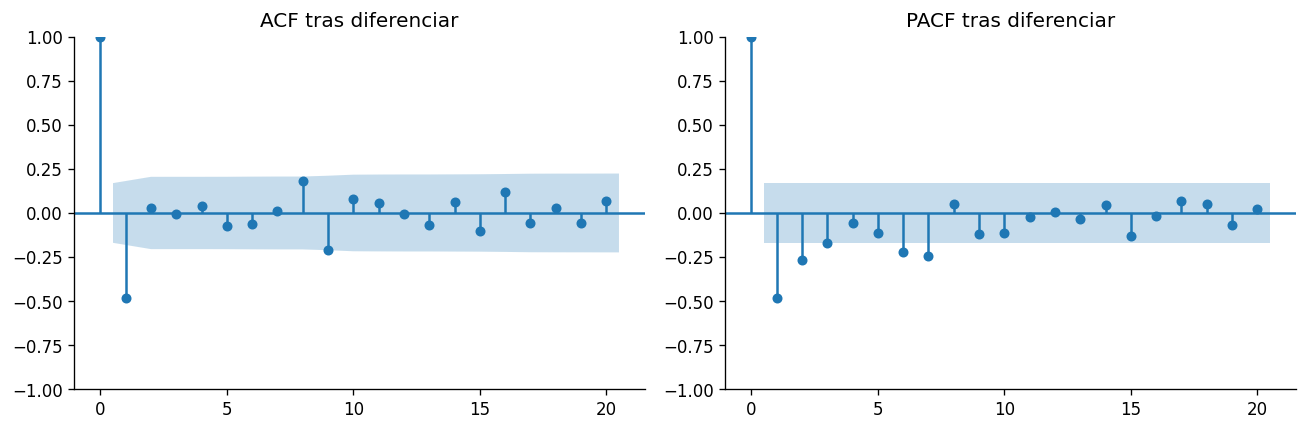

In [7]:
fig,axs=plt.subplots(1,2,figsize=(11,3.7))
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
plot_acf(z,ax=axs[0],lags=20);plot_pacf(z,ax=axs[1],lags=20,method='ywm');axs[0].set_title('ACF tras diferenciar');axs[1].set_title('PACF tras diferenciar');plt.tight_layout();plt.show()
fit_results={};records=[]
for p in range(3):
    for q in range(3):
        order=(p,d,q)
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                fit=ARIMA(train.to_numpy(),order=order,trend='n' if d else 'c',enforce_stationarity=True,enforce_invertibility=True).fit()
            converged=fit.mle_retvals.get('converged',False)
            records.append({'p':p,'d':d,'q':q,'AIC':fit.aic,'BIC':fit.bic,'Convergió':converged})
            if converged: fit_results[order]=fit
        except Exception as exc:
            records.append({'p':p,'d':d,'q':q,'AIC':np.nan,'BIC':np.nan,'Convergió':False})
            print(f'{order}: {type(exc).__name__}: {exc}')
models=pd.DataFrame(records).sort_values('AIC',na_position='last').reset_index(drop=True)
display(models.round(3))
assert len(fit_results)>=6, 'Menos de 6 modelos convergentes'
valid=models.loc[models['Convergió'] & models['AIC'].notna()]
best=valid.iloc[0]; order=tuple(int(best[k]) for k in ['p','d','q']); result=fit_results[order]
print(f'Modelo elegido ARIMA{order}, AIC={result.aic:.3f}, BIC={result.bic:.3f}; {len(valid)} candidatos convergentes.')
print(result.summary())

## 4. Diagnóstico de residuos
Buscamos dependencia temporal remanente con Ljung-Box. Si aparece autocorrelación, el modelo no captura toda la estructura aunque sea el mejor por AIC dentro de la cuadrícula. La selección no implica garantía predictiva.

Ljung-Box a 10 rezagos: sin evidencia de autocorrelación residual (nivel 5 %).


,Estadístico LB,p LB
10,1.1618,0.999


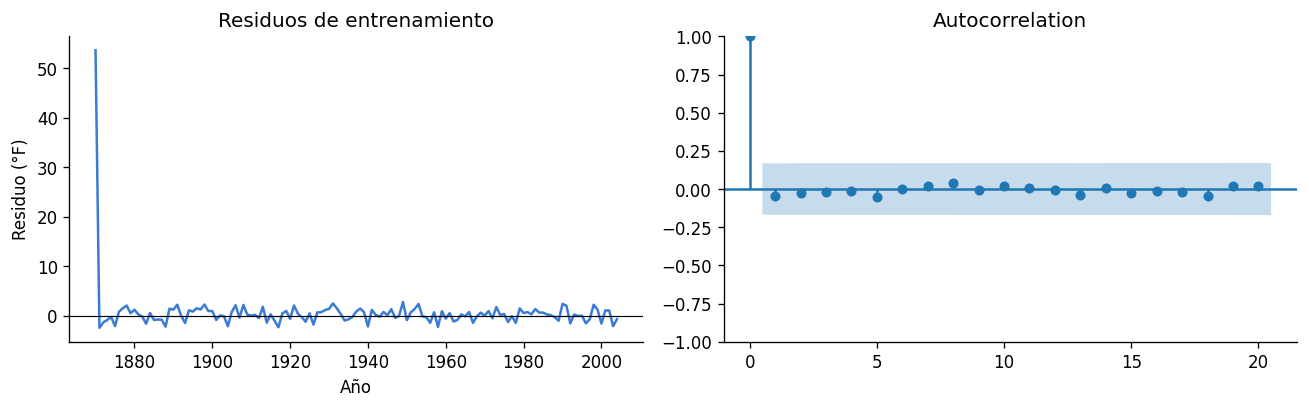

In [9]:
resid=pd.Series(result.resid,index=train.index)
lag=10
lb=acorr_ljungbox(resid,lags=[lag],model_df=order[0]+order[2],return_df=True)
display(lb.rename(columns={'lb_stat':'Estadístico LB','lb_pvalue':'p LB'}).round(4))
fig,axs=plt.subplots(1,2,figsize=(11,3.5));axs[0].plot(resid.index,resid,color=AZUL);axs[0].axhline(0,color='black',lw=.7);axs[0].set(xlabel='Año',ylabel='Residuo (°F)',title='Residuos de entrenamiento');plot_acf(resid,ax=axs[1],lags=20);plt.tight_layout();plt.show()
print('Ljung-Box a 10 rezagos: '+('hay evidencia de autocorrelación residual' if lb['lb_pvalue'].iloc[0]<.05 else 'sin evidencia de autocorrelación residual')+' (nivel 5 %).')

## 5. Pronóstico genuino fuera de muestra
Se proyectan de una vez los 16 años de prueba desde **finales de 2004**, sin incorporar valores reales posteriores. Las bandas son intervalos de **predicción** marginales del 90 % para cada año, no intervalos de confianza para una media estimada. Se asignan los años de prueba explícitamente para evitar errores de índice.

,Real (°F),Pronóstico (°F),Límite inferior 90 %,Límite superior 90 %,Error (°F)
Año,,,,,
2005,55.72,55.1,53.13,57.07,0.62
2006,56.79,55.1,53.11,57.09,1.69
2007,55.01,55.1,53.09,57.11,-0.09
2008,55.32,55.1,53.07,57.13,0.22
2009,54.02,55.1,53.05,57.15,-1.08
2010,56.69,55.1,53.03,57.17,1.59
2011,56.41,55.1,53.01,57.19,1.31
2012,57.31,55.1,52.99,57.21,2.21
2013,55.32,55.1,52.97,57.23,0.22


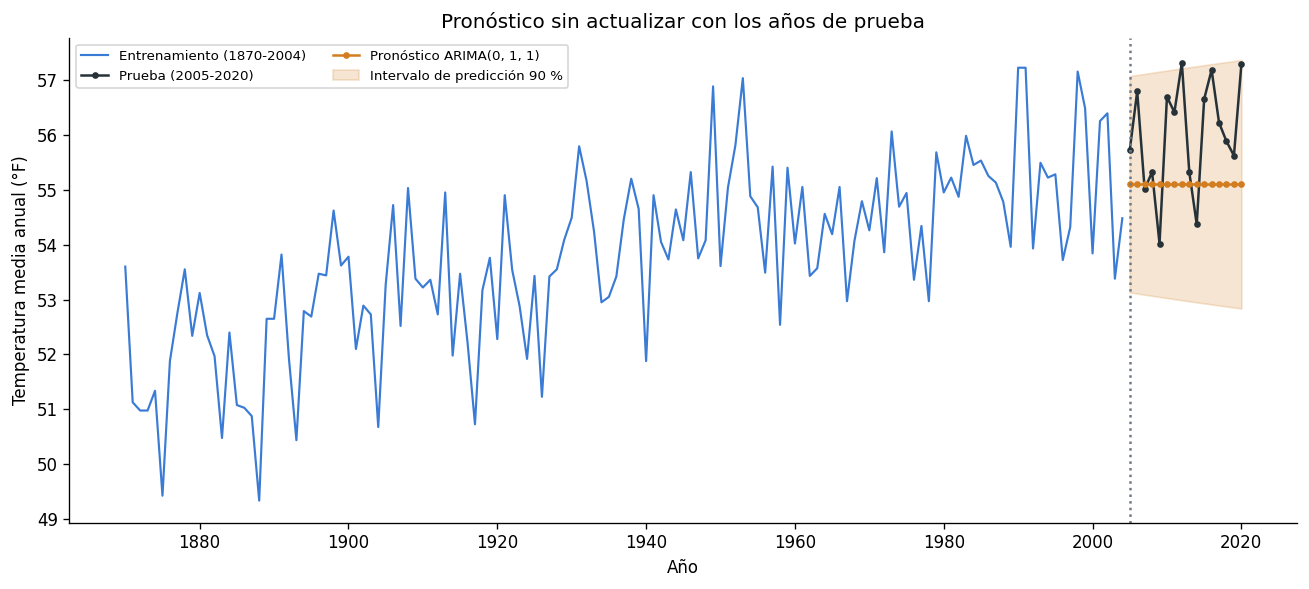

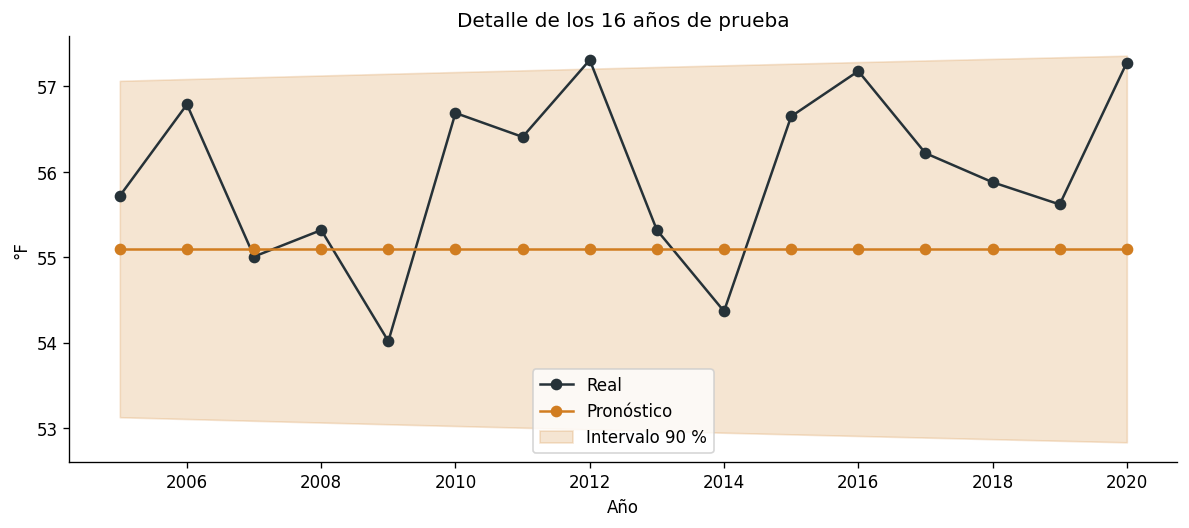

In [11]:
fc=result.get_forecast(steps=len(test)); pred=pd.Series(np.asarray(fc.predicted_mean),index=test.index,name='Pronóstico (°F)')
ci=np.asarray(fc.conf_int(alpha=.10)); low=pd.Series(ci[:,0],index=test.index); high=pd.Series(ci[:,1],index=test.index)
comparison=pd.DataFrame({'Real (°F)':test,'Pronóstico (°F)':pred,'Límite inferior 90 %':low,'Límite superior 90 %':high,'Error (°F)':test-pred})
display(comparison.round(2))
fig,ax=plt.subplots(figsize=(11,5));ax.plot(train.index,train,color=AZUL,lw=1.3,label='Entrenamiento (1870-2004)');ax.plot(test.index,test,color='#263238',marker='o',ms=3,label='Prueba (2005-2020)');ax.plot(pred.index,pred,color='#D17D20',marker='.',label=f'Pronóstico ARIMA{order}');ax.fill_between(test.index,low.to_numpy(),high.to_numpy(),color='#D17D20',alpha=.2,label='Intervalo de predicción 90 %');ax.axvline(2005,color=GRIS,ls=':');ax.set(xlabel='Año',ylabel='Temperatura media anual (°F)',title='Pronóstico sin actualizar con los años de prueba');ax.legend(loc='upper left',fontsize=8,ncol=2);plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(10,4.5));ax.plot(test.index,test,color='#263238',marker='o',label='Real');ax.plot(pred.index,pred,color='#D17D20',marker='o',label='Pronóstico');ax.fill_between(test.index,low.to_numpy(),high.to_numpy(),color='#D17D20',alpha=.2,label='Intervalo 90 %');ax.set(xlabel='Año',ylabel='°F',title='Detalle de los 16 años de prueba');ax.legend();plt.tight_layout();plt.show()

## 6. Exactitud y evaluación crítica
MAE y RMSE están en °F; RMSE castiga más los errores grandes. MAPE expresa el error relativo como porcentaje, pero depende de la escala Fahrenheit y no es comparable con un MAPE calculado tras convertir a Celsius. También calculamos sesgo, cobertura del intervalo, amplitud media y una referencia ingenua: repetir la temperatura de 2004 durante todo el horizonte. La referencia se evalúa sobre **los mismos 16 años**, sin filtración de datos futuros. AIC no se calcula sobre el conjunto de prueba.

In [13]:
naive=np.repeat(train.iloc[-1],len(test))
def metrics(actual,forecast):
    err=np.asarray(actual)-np.asarray(forecast)
    return {'MAE (°F)':np.mean(np.abs(err)),'RMSE (°F)':np.sqrt(np.mean(err**2)),'MAPE (%)':100*np.mean(np.abs(err/np.asarray(actual))),'Sesgo real - pronóstico (°F)':np.mean(err)}
met=pd.DataFrame({'ARIMA':metrics(test,pred),'Naive último año':metrics(test,naive)}).T
coverage=((test>=low)&(test<=high)).mean();width=(high-low).mean()
display(met.round(3));print(f'Cobertura del intervalo 90 %: {coverage:.1%} ({int(((test>=low)&(test<=high)).sum())}/{len(test)}); amplitud media: {width:.2f} °F.')
print(f'RMSE ARIMA = {met.loc["ARIMA","RMSE (°F)"]:.2f} °F; referencia = {met.loc["Naive último año","RMSE (°F)"]:.2f} °F; mejora relativa = {100*(1-met.loc["ARIMA","RMSE (°F)"]/met.loc["Naive último año","RMSE (°F)"]):.1f} %.')
print('CONCLUSIÓN: '+('ARIMA reduce el RMSE respecto a la referencia; ' if met.loc['ARIMA','RMSE (°F)']<met.loc['Naive último año','RMSE (°F)'] else 'ARIMA NO supera a la referencia en RMSE; ')+f'cobertura observada {coverage:.1%}. '+('La cobertura es inferior al 90 % nominal; ' if coverage<.9 else 'La cobertura observada alcanza o excede el 90 % nominal; ')+'con solo 16 años hay incertidumbre considerable en esa estimación. Una predicción útil depende de la tolerancia operativa al error; AIC mínimo y p de ADF no bastan para declarar pronósticos confiables. Se sugiere validar con varios orígenes temporales y probar deriva/tendencia y covariables climáticas antes de usar el modelo en decisiones.')

Cobertura del intervalo 90 %: 93.8% (15/16); amplitud media: 4.24 °F.
RMSE ARIMA = 1.32 °F; referencia = 1.79 °F; mejora relativa = 26.5 %.
CONCLUSIÓN: ARIMA reduce el RMSE respecto a la referencia; cobertura observada 93.8%. La cobertura observada alcanza o excede el 90 % nominal; con solo 16 años hay incertidumbre considerable en esa estimación. Una predicción útil depende de la tolerancia operativa al error; AIC mínimo y p de ADF no bastan para declarar pronósticos confiables. Se sugiere validar con varios orígenes temporales y probar deriva/tendencia y covariables climáticas antes de usar el modelo en decisiones.


,MAE (°F),RMSE (°F),MAPE (%),Sesgo real - pronóstico (°F)
ARIMA,1.125,1.319,1.994,0.889
Naive último año,1.578,1.795,2.793,1.507


### Alcance y referencias
- Los intervalos se basan en los supuestos probabilísticos del ARIMA; no cuantifican cambios estructurales climáticos o errores de medición.
- Box, G. E. P. et al., *Time Series Analysis: Forecasting and Control*; documentación de `statsmodels` (`adfuller`, `ARIMA`, `get_forecast`): https://www.statsmodels.org/stable/tsa.html.
- Fuente de los datos: enlace del CSV indicado en la consigna. Archivo adjunto conservado sin modificar.